# Analyse av måledata – Sharp GP2Y0A02YK0F vs. Maxbotix LV-EZ0

Notebooken har ett plott per datafil, og til slutt noen sammenligninger der filene hører sammen
(lys/mørke, Sharp/ultralyd, ulike hindringer).

**Merk:** Legg CSV-filene i mappen `data/` (eller endre `DATA_DIR`), og juster filnavnene i `FILER` hvis de heter noe annet hos deg.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import medfilt

DATA_DIR = Path("data")

FILER = {
    "sharp_1":        "måleserie 1 sharp.csv",
    "ultra_1":        "måleserie 1 ultrasonic.csv",
    "sharp_2":        "måleserie 2 sharp.csv",
    "sharp_3":        "måleserie 3 sharp.csv",
    "sharp_lys":      "måleserie 20 cm intervaller i lys.csv",
    "ultra_lys":      "måleserie 20 cm intervaller i lys ultrasonic.csv",
    "sharp_mork":     "måleserie 20 cm intervaller i mørket.csv",
    "ultra_mork":     "målerserie 20 cm intervaller i mørket ultrasonic.csv",
    "sharp_treplate": "treplate 20 cm intervall.csv",
    "sharp_flaske":   "vannflaske sharp.csv",
}

def les(fil):
    """Leser CSV med eller uten header (Tid, Spenning, Distanse)."""
    df = pd.read_csv(DATA_DIR / fil, header=None, names=["t", "V", "d"])
    df = df[pd.to_numeric(df["t"], errors="coerce").notna()].astype(float)
    return df.reset_index(drop=True)

data = {navn: les(fil) for navn, fil in FILER.items()}

FARGE = {"sharp": "#1f77b4", "ultra": "#d62728"}
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3})

for navn, df in data.items():
    print(f"{navn:15s} {len(df):4d} prøver  d: {df.d.min():6.1f} – {df.d.max():6.1f} cm")

sharp_1          115 prøver  d:   15.5 –   77.2 cm
ultra_1          200 prøver  d:   17.4 –   97.7 cm
sharp_2          212 prøver  d:   16.6 –   99.2 cm
sharp_3          183 prøver  d:   16.4 –   92.7 cm
sharp_lys         57 prøver  d:   18.7 –   93.9 cm
ultra_lys         41 prøver  d:   20.9 –  100.4 cm
sharp_mork        37 prøver  d:   19.5 –   93.2 cm
ultra_mork        55 prøver  d:   20.9 –  102.4 cm
sharp_treplate    70 prøver  d:   19.6 –   83.7 cm
sharp_flaske     393 prøver  d:   16.8 –   69.8 cm


## Hjelpefunksjoner

`plott_tid` tegner distanse og spenning mot tid (to y-akser).
For trinnmålingene (20 cm intervaller) er de stabile platåene definert manuelt med tidsintervall og referanseavstand.
`platå_tabell` beregner middelverdi, standardavvik og avvik fra referansen for hvert platå.

In [8]:
def plott_tid(df, tittel, farge, ax=None):
    if ax is None:
        fig, ax = plt.subplots()
    ax.plot(df.t, df.d, "-o", ms=3, color=farge, label="Distanse")
    ax.set_xlabel("Tid [s]"); ax.set_ylabel("Distanse [cm]", color=farge)
    ax2 = ax.twinx()
    ax2.plot(df.t, df.V, "--", color="gray", alpha=0.7, label="Spenning")
    ax2.set_ylabel("Spenning [V]", color="gray"); ax2.grid(False)
    ax.set_title(tittel)
    return ax, ax2

def platå_tabell(df, platåer):
    """platåer: liste med (t_start, t_slutt, referanse_cm, retning)"""
    rader = []
    for t0, t1, ref, retning in platåer:
        seg = df[(df.t >= t0) & (df.t <= t1)]
        rader.append({"ref [cm]": ref, "retning": retning, "t": f"{t0}-{t1}",
                      "middel [cm]": seg.d.mean(), "std [cm]": seg.d.std(),
                      "V middel [V]": seg.V.mean(), "avvik [cm]": seg.d.mean() - ref})
    return pd.DataFrame(rader)

def marker_platåer(ax, platåer, farge):
    for t0, t1, ref, _ in platåer:
        ax.axvspan(t0, t1, color=farge, alpha=0.08)
        ax.hlines(ref, t0, t1, colors="k", linestyles=":", lw=1)

def hysterese(tab):
    opp = tab[tab.retning == "opp"].set_index("ref [cm]")["middel [cm]"]
    ned = tab[tab.retning == "ned"].set_index("ref [cm]")["middel [cm]"]
    h = (ned - opp).dropna()
    return pd.DataFrame({"opp [cm]": opp[h.index], "ned [cm]": ned[h.index], "ned - opp [cm]": h})

## 1. Måleserie 1 – Sharp

Kontinuerlig bevegelse av objektet frem og tilbake. Merk området rundt 15–17 cm: under ca. 15–20 cm
er Sharp-sensoren i dødsonen sin, der kurven «bretter seg» og verdien øker igjen selv om objektet er nærmere
(se f.eks. t ≈ 12–14 s og hoppet ved t ≈ 104–108 s).

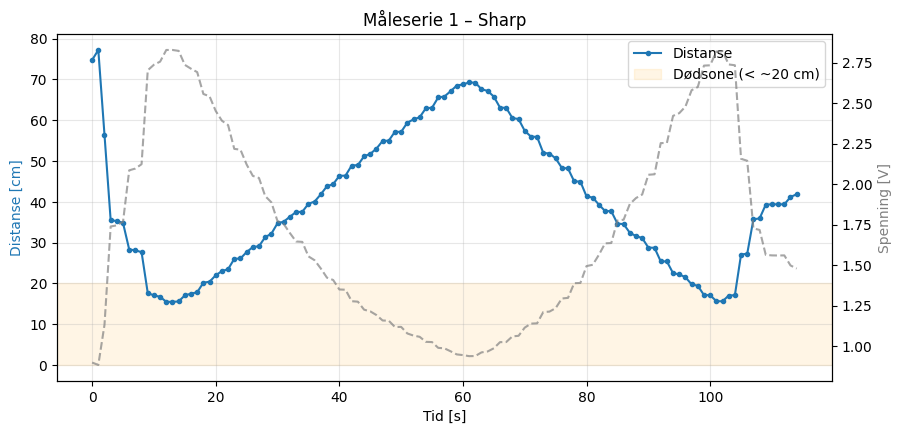

In [9]:
df = data["sharp_1"]
ax, _ = plott_tid(df, "Måleserie 1 – Sharp", FARGE["sharp"])
ax.axhspan(0, 20, color="orange", alpha=0.1, label="Dødsone (< ~20 cm)")
ax.legend(loc="upper right")
plt.show()

## 2. Måleserie 1 – Ultralyd (LV-EZ0)

Sweep fra nærmeste posisjon ut til ca. 97 cm og tilbake. Ved start og slutt ligger målingen flatt på ~17,5 cm,
som tyder på sensorens minimumsavstand (dødsone): alt nærmere rapporteres som samme verdi.

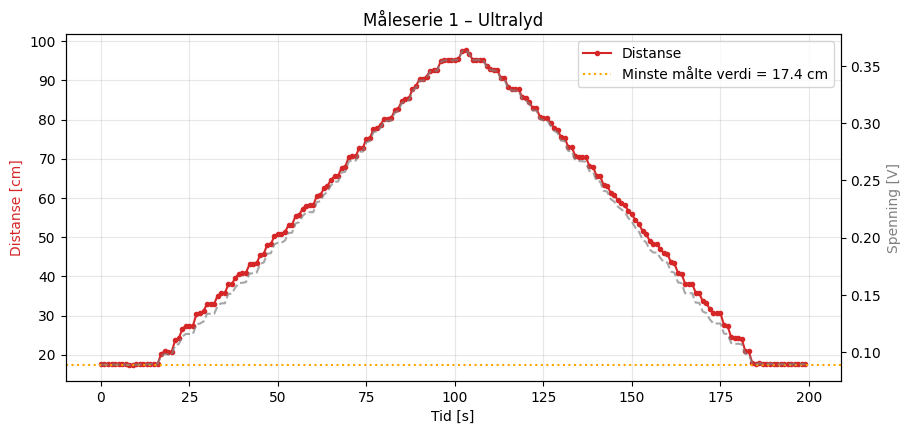

In [10]:
df = data["ultra_1"]
ax, _ = plott_tid(df, "Måleserie 1 – Ultralyd", FARGE["ultra"])
ax.axhline(df.d.min(), color="orange", ls=":", label=f"Minste målte verdi = {df.d.min():.1f} cm")
ax.legend(loc="upper right")
plt.show()

## 3. Måleserie 2 – Sharp

Sweep ca. 17 → 99 → 17 cm. Kurven er glatt i nærområdet, men blir mer støyete over ~80 cm,
der Sharp-kurven er flat (liten endring i spenning per cm → lav sensitivitet).

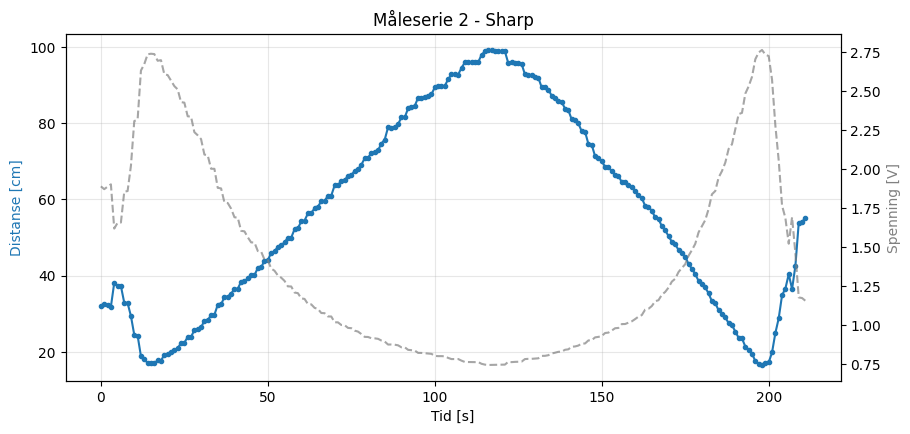

In [13]:
df = data["sharp_2"]
ax, _ = plott_tid(df, "Måleserie 2 - Sharp", FARGE["sharp"])
plt.show()

## 4. Måleserie 3 – Sharp

Samme type sweep. Rundt t ≈ 88–105 s (lengst unna, ~85–92 cm) ses tydelige spikes – typisk for Sharp
i ytterkant av måleområdet. Et medianfilter (vindu 5) er lagt på for å vise hvordan dette kan dempes.

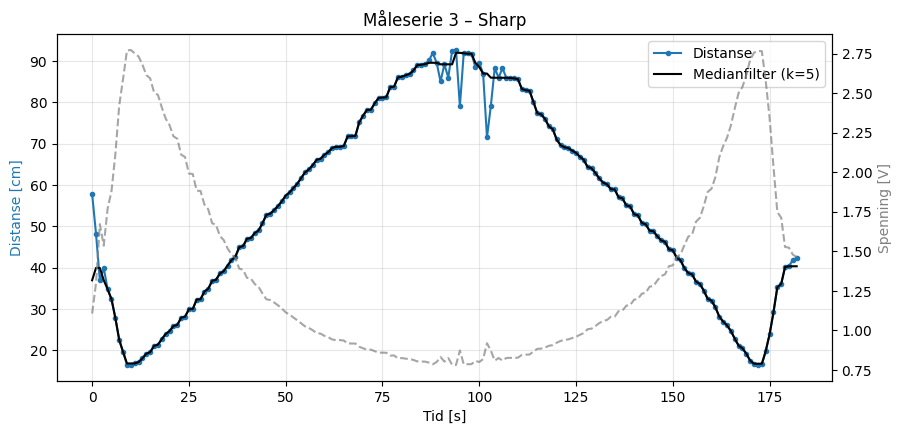

In [14]:
df = data["sharp_3"]
ax, _ = plott_tid(df, "Måleserie 3 – Sharp", FARGE["sharp"])
ax.plot(df.t, medfilt(df.d, 5), color="k", lw=1.5, label="Medianfilter (k=5)")
ax.legend(loc="upper right")
plt.show()

## 5. 20 cm intervaller i lys – Sharp

Objektet flyttes i trinn 20 → 100 → 20 cm. Grå felt viser platåene som brukes i beregningene,
stiplet linje er referanseavstanden.

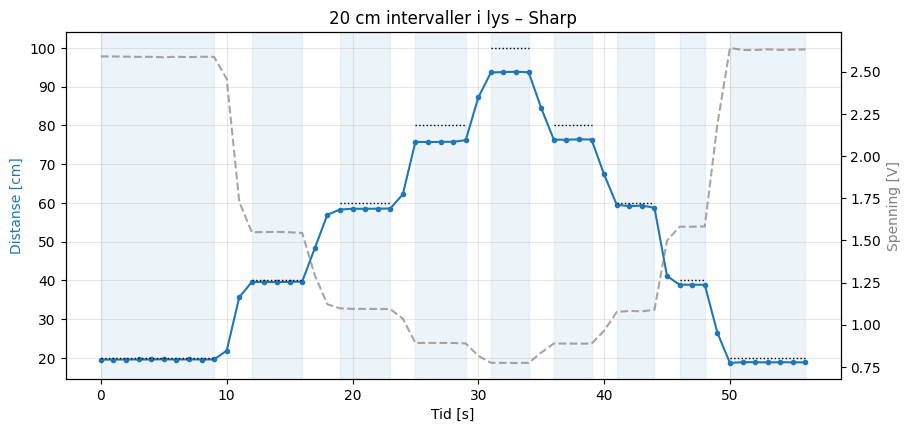

,ref [cm],retning,t,middel [cm],std [cm],V middel [V],avvik [cm]
0,20,opp,0-9,19.61,0.03,2.59,-0.39
1,40,opp,12-16,39.64,0.06,1.55,-0.36
2,60,opp,19-23,58.48,0.10,1.10,-1.52
3,80,opp,25-29,75.85,0.20,0.89,-4.15
4,100,opp,31-34,93.76,0.08,0.77,-6.24
5,80,ned,36-39,76.36,0.05,0.89,-3.64
6,60,ned,41-44,59.21,0.32,1.08,-0.79
7,40,ned,46-48,38.90,0.02,1.58,-1.10
8,20,ned,50-56,18.86,0.07,2.63,-1.14


In [15]:
P_SHARP_LYS = [(0, 9, 20, "opp"), (12, 16, 40, "opp"), (19, 23, 60, "opp"), (25, 29, 80, "opp"),
               (31, 34, 100, "opp"), (36, 39, 80, "ned"), (41, 44, 60, "ned"), (46, 48, 40, "ned"),
               (50, 56, 20, "ned")]
df = data["sharp_lys"]
ax, _ = plott_tid(df, "20 cm intervaller i lys – Sharp", FARGE["sharp"])
marker_platåer(ax, P_SHARP_LYS, FARGE["sharp"])
plt.show()
tab_sharp_lys = platå_tabell(df, P_SHARP_LYS)
tab_sharp_lys.round(2)

## 6. 20 cm intervaller i lys – Ultralyd

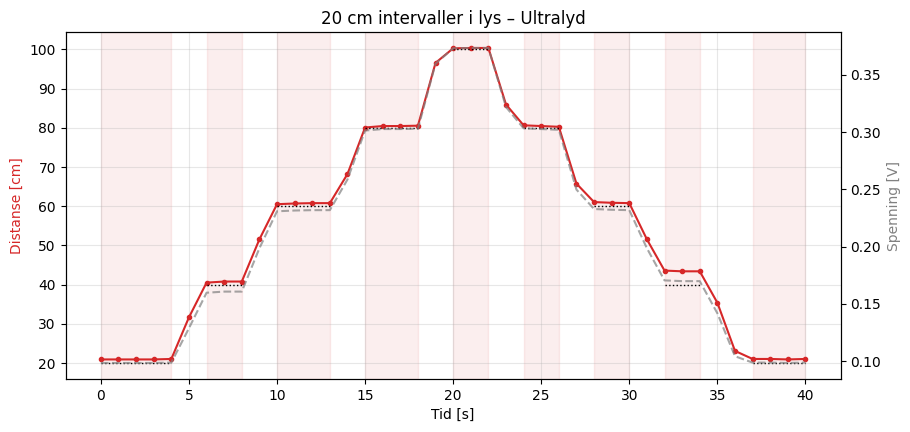

,ref [cm],retning,t,middel [cm],std [cm],V middel [V],avvik [cm]
0,20,opp,0-4,20.93,0.05,0.10,0.93
1,40,opp,6-8,40.68,0.16,0.16,0.68
2,60,opp,10-13,60.69,0.13,0.23,0.69
3,80,opp,15-18,80.37,0.21,0.30,0.37
4,100,opp,20-22,100.33,0.05,0.37,0.33
5,80,ned,24-26,80.44,0.19,0.30,0.44
6,60,ned,28-30,60.90,0.14,0.23,0.90
7,40,ned,32-34,43.45,0.11,0.17,3.45
8,20,ned,37-40,20.99,0.06,0.10,0.99


In [16]:
P_ULTRA_LYS = [(0, 4, 20, "opp"), (6, 8, 40, "opp"), (10, 13, 60, "opp"), (15, 18, 80, "opp"),
               (20, 22, 100, "opp"), (24, 26, 80, "ned"), (28, 30, 60, "ned"), (32, 34, 40, "ned"),
               (37, 40, 20, "ned")]
df = data["ultra_lys"]
ax, _ = plott_tid(df, "20 cm intervaller i lys – Ultralyd", FARGE["ultra"])
marker_platåer(ax, P_ULTRA_LYS, FARGE["ultra"])
plt.show()
tab_ultra_lys = platå_tabell(df, P_ULTRA_LYS)
tab_ultra_lys.round(2)

## 7. 20 cm intervaller i mørket – Sharp

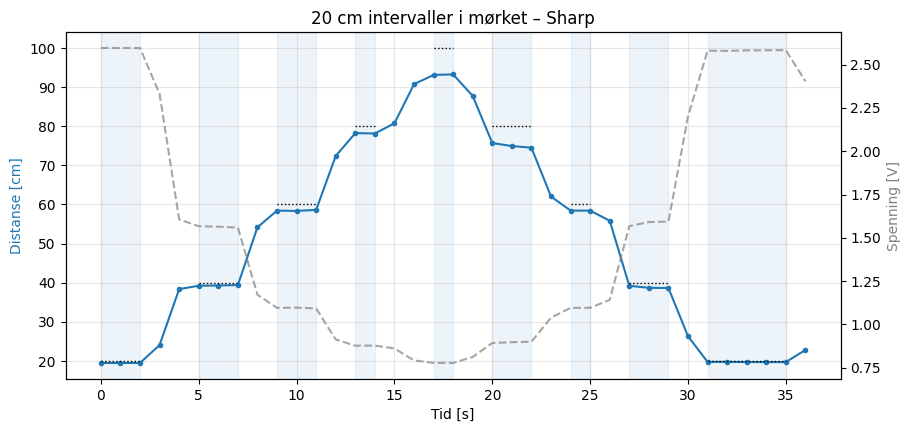

,ref [cm],retning,t,middel [cm],std [cm],V middel [V],avvik [cm]
0,20,opp,0-2,19.49,0.00,2.60,-0.51
1,40,opp,5-7,39.31,0.09,1.56,-0.69
2,60,opp,9-11,58.47,0.14,1.10,-1.53
3,80,opp,13-14,78.19,0.08,0.88,-1.81
4,100,opp,17-18,93.17,0.08,0.78,-6.83
5,80,ned,20-22,75.04,0.61,0.90,-4.96
6,60,ned,24-25,58.43,0.01,1.10,-1.57
7,40,ned,27-29,38.85,0.32,1.58,-1.15
8,20,ned,31-35,19.74,0.03,2.58,-0.26


In [17]:
P_SHARP_MORK = [(0, 2, 20, "opp"), (5, 7, 40, "opp"), (9, 11, 60, "opp"), (13, 14, 80, "opp"),
                (17, 18, 100, "opp"), (20, 22, 80, "ned"), (24, 25, 60, "ned"), (27, 29, 40, "ned"),
                (31, 35, 20, "ned")]
df = data["sharp_mork"]
ax, _ = plott_tid(df, "20 cm intervaller i mørket – Sharp", FARGE["sharp"])
marker_platåer(ax, P_SHARP_MORK, FARGE["sharp"])
plt.show()
tab_sharp_mork = platå_tabell(df, P_SHARP_MORK)
tab_sharp_mork.round(2)

## 8. 20 cm intervaller i mørket – Ultralyd

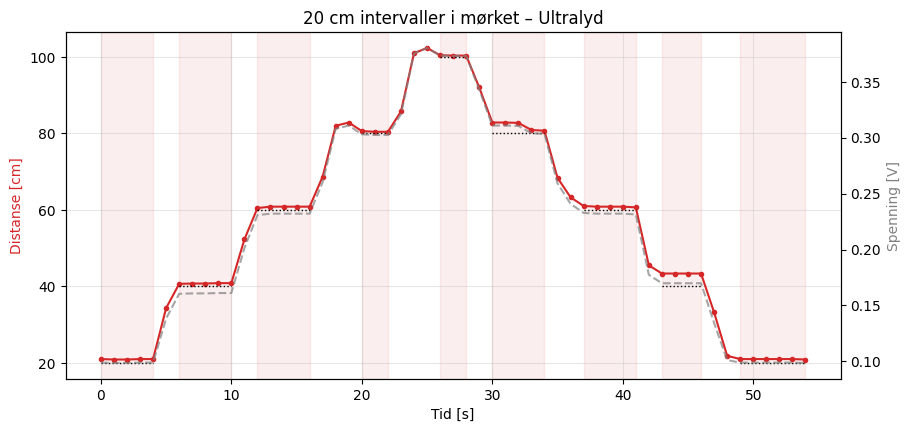

,ref [cm],retning,t,middel [cm],std [cm],V middel [V],avvik [cm]
0,20,opp,0-4,20.97,0.07,0.10,0.97
1,40,opp,6-10,40.79,0.08,0.16,0.79
2,60,opp,12-16,60.79,0.16,0.23,0.79
3,80,opp,20-22,80.51,0.11,0.30,0.51
4,100,opp,26-28,100.39,0.05,0.37,0.39
5,80,ned,30-34,82.03,1.11,0.31,2.03
6,60,ned,37-41,60.87,0.13,0.23,0.87
7,40,ned,43-46,43.38,0.00,0.17,3.38
8,20,ned,49-54,21.00,0.05,0.10,1.00


In [18]:
P_ULTRA_MORK = [(0, 4, 20, "opp"), (6, 10, 40, "opp"), (12, 16, 60, "opp"), (20, 22, 80, "opp"),
                (26, 28, 100, "opp"), (30, 34, 80, "ned"), (37, 41, 60, "ned"), (43, 46, 40, "ned"),
                (49, 54, 20, "ned")]
df = data["ultra_mork"]
ax, _ = plott_tid(df, "20 cm intervaller i mørket – Ultralyd", FARGE["ultra"])
marker_platåer(ax, P_ULTRA_MORK, FARGE["ultra"])
plt.show()
tab_ultra_mork = platå_tabell(df, P_ULTRA_MORK)
tab_ultra_mork.round(2)

## 9. Treplate, 20 cm intervaller – Sharp

Kun målinger utover. **Antakelse:** trinnene er 20, 40, 60, 80 og 100 cm (juster `P_TREPLATE` hvis ikke).

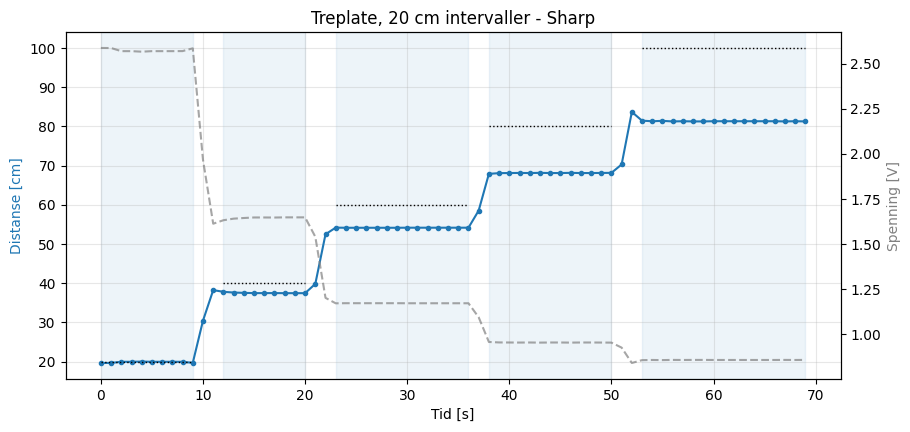

,ref [cm],retning,t,middel [cm],std [cm],V middel [V],avvik [cm]
0,20,opp,0-9,19.86,0.14,2.57,-0.14
1,40,opp,12-20,37.52,0.12,1.64,-2.48
2,60,opp,23-36,54.14,0.01,1.17,-5.86
3,80,opp,38-50,68.09,0.07,0.95,-11.91
4,100,opp,53-69,81.31,0.05,0.86,-18.69


In [20]:
P_TREPLATE = [(0, 9, 20, "opp"), (12, 20, 40, "opp"), (23, 36, 60, "opp"),
              (38, 50, 80, "opp"), (53, 69, 100, "opp")]
df = data["sharp_treplate"]
ax, _ = plott_tid(df, "Treplate, 20 cm intervaller - Sharp", FARGE["sharp"])
marker_platåer(ax, P_TREPLATE, FARGE["sharp"])
plt.show()
tab_treplate = platå_tabell(df, P_TREPLATE)
tab_treplate.round(2)

## 10. Vannflaske – Sharp

Målingen ligger stort sett rundt 52 cm, men med mange kortvarige avvik (hopp til 17–70 cm).
Her vises rådata sammen med medianfilter og glidende middel for å illustrere filtrering av signalet.

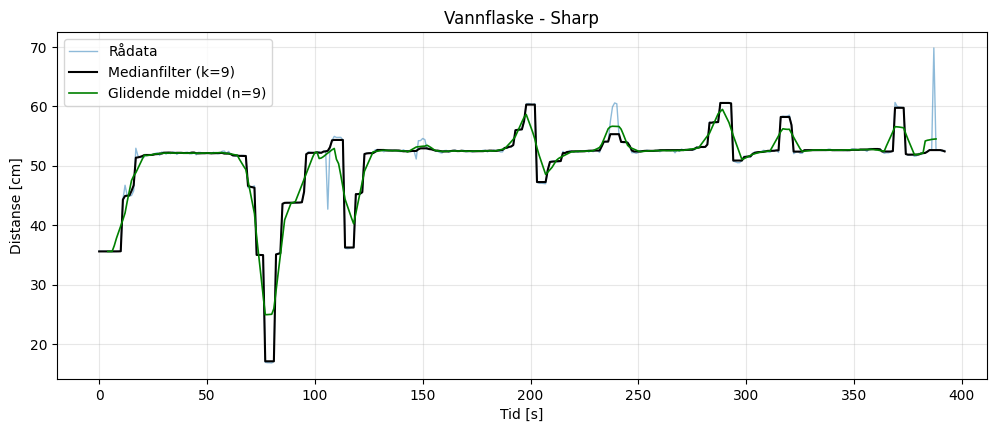

Stabil del (t=18-68 s): middel = 52.01 cm, std = 0.27 cm
Hele serien:           std rå = 6.36 cm, std median = 6.19 cm


In [21]:
df = data["sharp_flaske"]
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(df.t, df.d, color=FARGE["sharp"], alpha=0.5, lw=1, label="Rådata")
ax.plot(df.t, medfilt(df.d, 9), color="k", lw=1.5, label="Medianfilter (k=9)")
ax.plot(df.t, df.d.rolling(9, center=True).mean(), color="green", lw=1.2, label="Glidende middel (n=9)")
ax.set_xlabel("Tid [s]"); ax.set_ylabel("Distanse [cm]")
ax.set_title("Vannflaske - Sharp"); ax.legend()
plt.show()

stabil = df[(df.t >= 18) & (df.t <= 68)]
print(f"Stabil del (t=18-68 s): middel = {stabil.d.mean():.2f} cm, std = {stabil.d.std():.2f} cm")
print(f"Hele serien:           std rå = {df.d.std():.2f} cm, std median = {np.std(medfilt(df.d, 9)):.2f} cm")

## Sammenligning 1 – Karakteristikk og sensitivitet (spenning vs. avstand)

Data fra sweep-seriene. Sharp har en sterkt ulineær (omtrent invers) karakteristikk, mens ultralyd er tilnærmet lineær.
Sensitiviteten $S = dV/dd$ beregnes fra platå-middelverdiene i lys-seriene.

Sharp     |S| per intervall [mV/cm]: [52.24 23.84  9.89  5.8 ]
Ultralyd  |S| per intervall [mV/cm]: [3.33 3.33 3.53 3.54]


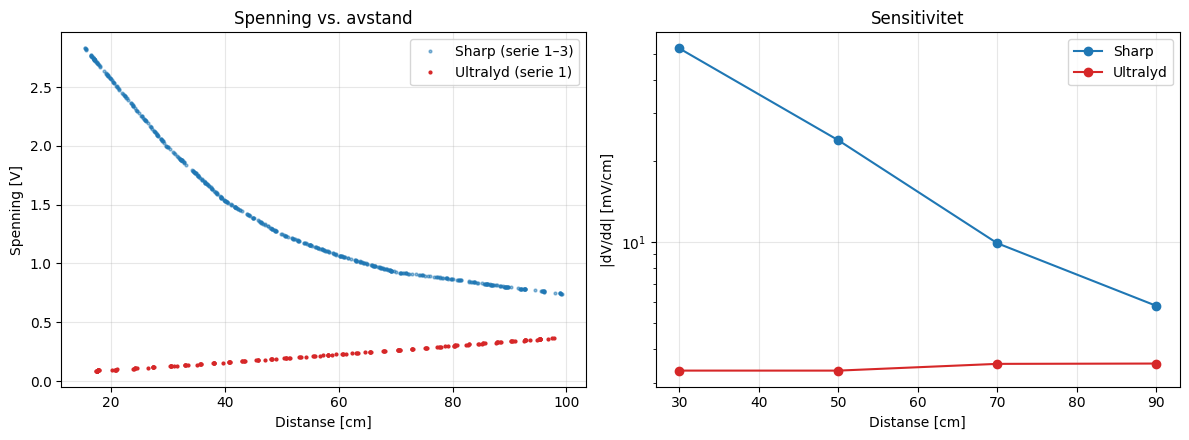

In [22]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
for i, navn in enumerate(["sharp_1", "sharp_2", "sharp_3"]):
    a1.plot(data[navn].d, data[navn].V, ".", ms=4, color=FARGE["sharp"], alpha=0.5,
            label="Sharp (serie 1–3)" if i == 0 else None)
a1.plot(data["ultra_1"].d, data["ultra_1"].V, ".", ms=4, color=FARGE["ultra"], label="Ultralyd (serie 1)")
a1.set_xlabel("Distanse [cm]"); a1.set_ylabel("Spenning [V]")
a1.set_title("Spenning vs. avstand"); a1.legend()

for tab, navn, f in [(tab_sharp_lys, "Sharp", FARGE["sharp"]), (tab_ultra_lys, "Ultralyd", FARGE["ultra"])]:
    m = tab.groupby("ref [cm]")["V middel [V]"].mean()
    S = np.diff(m.values) / np.diff(m.index.values) * 1000  # mV/cm
    midt = (m.index.values[:-1] + m.index.values[1:]) / 2
    a2.plot(midt, np.abs(S), "o-", color=f, label=navn)
    print(f"{navn:9s} |S| per intervall [mV/cm]:", np.round(np.abs(S), 2))
a2.set_xlabel("Distanse [cm]"); a2.set_ylabel("|dV/dd| [mV/cm]")
a2.set_title("Sensitivitet"); a2.set_yscale("log"); a2.legend()
plt.tight_layout(); plt.show()

## Sammenligning 2 – Ulinearitet: målt vs. referanse (lys)

Avvik fra ideell linje (y = x). Ulinearitet oppgis som maks avvik i prosent av fullt måleområde (20–100 cm → 80 cm).

Sharp     maks avvik = 6.2 cm  → ulinearitet ≈ 7.8 % FS
Ultralyd  maks avvik = 3.4 cm  → ulinearitet ≈ 4.3 % FS


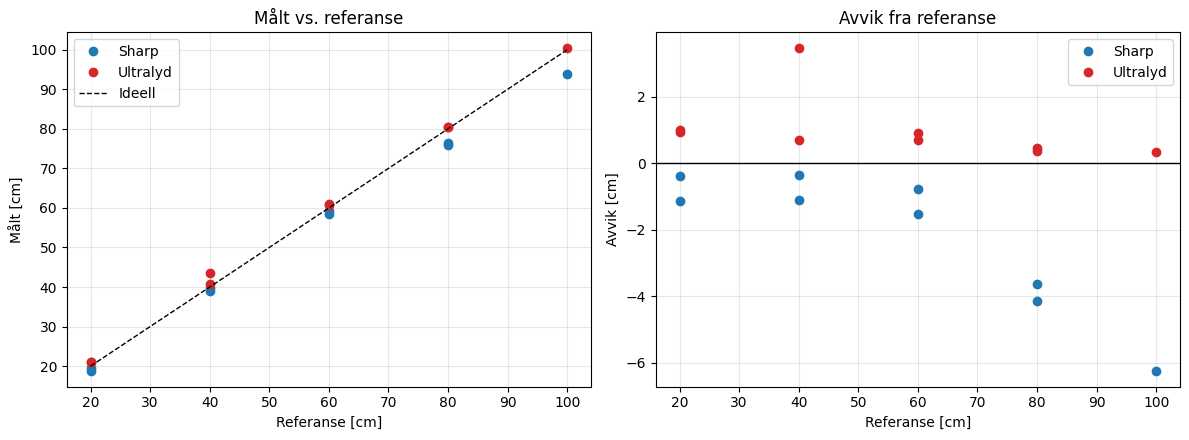

In [23]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
for tab, navn, f in [(tab_sharp_lys, "Sharp", FARGE["sharp"]), (tab_ultra_lys, "Ultralyd", FARGE["ultra"])]:
    a1.plot(tab["ref [cm]"], tab["middel [cm]"], "o", color=f, label=navn)
    a2.plot(tab["ref [cm]"], tab["avvik [cm]"], "o", color=f, label=navn)
    maks = tab["avvik [cm]"].abs().max()
    print(f"{navn:9s} maks avvik = {maks:.1f} cm  → ulinearitet ≈ {maks/80*100:.1f} % FS")
a1.plot([20, 100], [20, 100], "k--", lw=1, label="Ideell")
a1.set_xlabel("Referanse [cm]"); a1.set_ylabel("Målt [cm]"); a1.legend(); a1.set_title("Målt vs. referanse")
a2.axhline(0, color="k", lw=1)
a2.set_xlabel("Referanse [cm]"); a2.set_ylabel("Avvik [cm]"); a2.legend(); a2.set_title("Avvik fra referanse")
plt.tight_layout(); plt.show()

## Sammenligning 3 – Hysterese (opp vs. ned)

Differansen mellom målt verdi på vei ut og på vei inn ved samme referanseavstand.

Sharp lys       maks |hysterese| = 0.75 cm
Ultralyd lys    maks |hysterese| = 2.76 cm
Sharp mørke     maks |hysterese| = 3.14 cm
Ultralyd mørke  maks |hysterese| = 2.59 cm


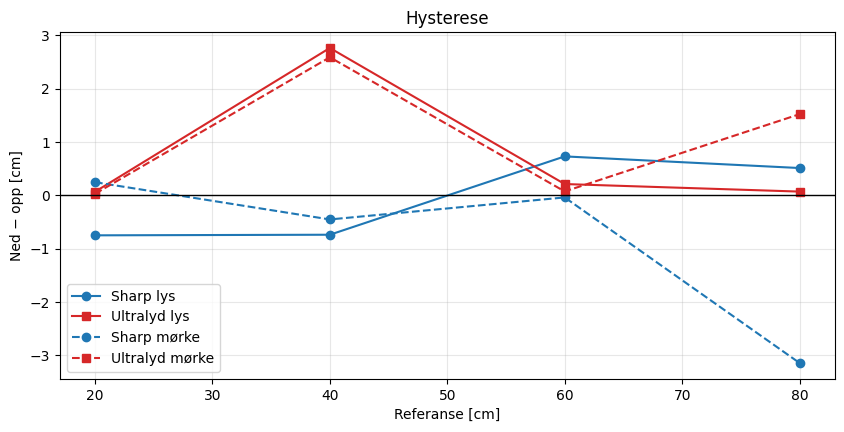

In [24]:
hyst = {"Sharp lys": hysterese(tab_sharp_lys), "Ultralyd lys": hysterese(tab_ultra_lys),
        "Sharp mørke": hysterese(tab_sharp_mork), "Ultralyd mørke": hysterese(tab_ultra_mork)}

fig, ax = plt.subplots()
for (navn, h), mk in zip(hyst.items(), ["o-", "s-", "o--", "s--"]):
    f = FARGE["sharp"] if "Sharp" in navn else FARGE["ultra"]
    ax.plot(h.index, h["ned - opp [cm]"], mk, color=f, label=navn)
    print(f"{navn:15s} maks |hysterese| = {h['ned - opp [cm]'].abs().max():.2f} cm")
ax.axhline(0, color="k", lw=1)
ax.set_xlabel("Referanse [cm]"); ax.set_ylabel("Ned − opp [cm]"); ax.set_title("Hysterese"); ax.legend()
plt.show()

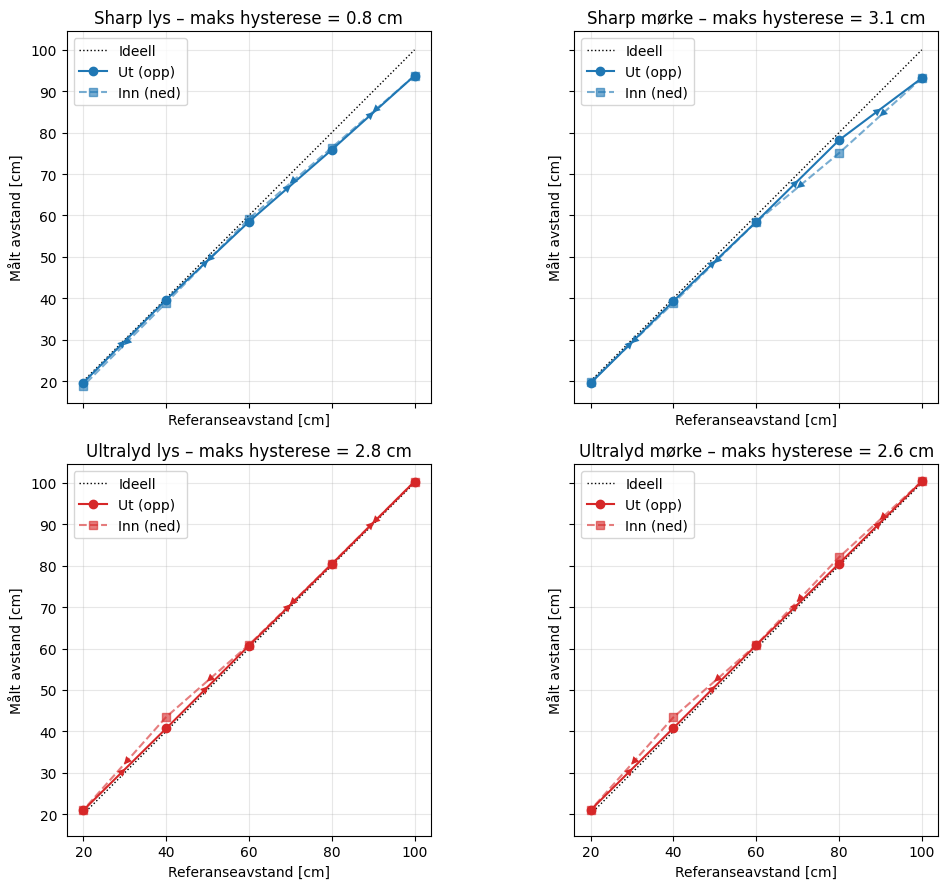

In [25]:
serier = [("Sharp lys", tab_sharp_lys, FARGE["sharp"]),
          ("Sharp mørke", tab_sharp_mork, FARGE["sharp"]),
          ("Ultralyd lys", tab_ultra_lys, FARGE["ultra"]),
          ("Ultralyd mørke", tab_ultra_mork, FARGE["ultra"])]

def pil(ax, x, y, farge):
    """Pil midt på hvert linjestykke som viser retning."""
    for i in range(len(x) - 1):
        ax.annotate("", xy=((x[i] + x[i+1]) / 2 + 0.01 * (x[i+1] - x[i]), (y[i] + y[i+1]) / 2 + 0.01 * (y[i+1] - y[i])),
                    xytext=((x[i] + x[i+1]) / 2, (y[i] + y[i+1]) / 2),
                    arrowprops=dict(arrowstyle="-|>", color=farge, lw=0, mutation_scale=14))

fig, axs = plt.subplots(2, 2, figsize=(11, 9), sharex=True, sharey=True)
for ax, (navn, tab, f) in zip(axs.flat, serier):
    opp = tab[tab.retning == "opp"].sort_values("ref [cm]")
    ned = tab[tab.retning == "ned"].sort_values("ref [cm]", ascending=False)
    # Lukk løkken: "ned" starter der "opp" slutter (100 cm)
    ned = pd.concat([opp.tail(1), ned])

    ax.plot([20, 100], [20, 100], "k:", lw=1, label="Ideell")
    ax.plot(opp["ref [cm]"], opp["middel [cm]"], "-o", color=f, label="Ut (opp)")
    ax.plot(ned["ref [cm]"], ned["middel [cm]"], "--s", color=f, alpha=0.6, label="Inn (ned)")
    pil(ax, opp["ref [cm]"].values, opp["middel [cm]"].values, f)
    pil(ax, ned["ref [cm]"].values, ned["middel [cm]"].values, f)

    h = hysterese(tab)["ned - opp [cm]"].abs().max()
    ax.set_title(f"{navn} – maks hysterese = {h:.1f} cm")
    ax.set_xlabel("Referanseavstand [cm]"); ax.set_ylabel("Målt avstand [cm]")
    ax.legend(loc="upper left")
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

## Sammenligning 4 – Lys vs. mørke

Sammenligner platå-middelverdiene for hver sensor i lys og mørke.

Sharp     middel |lys − mørke| = 0.41 cm
Ultralyd  middel |lys − mørke| = 0.20 cm


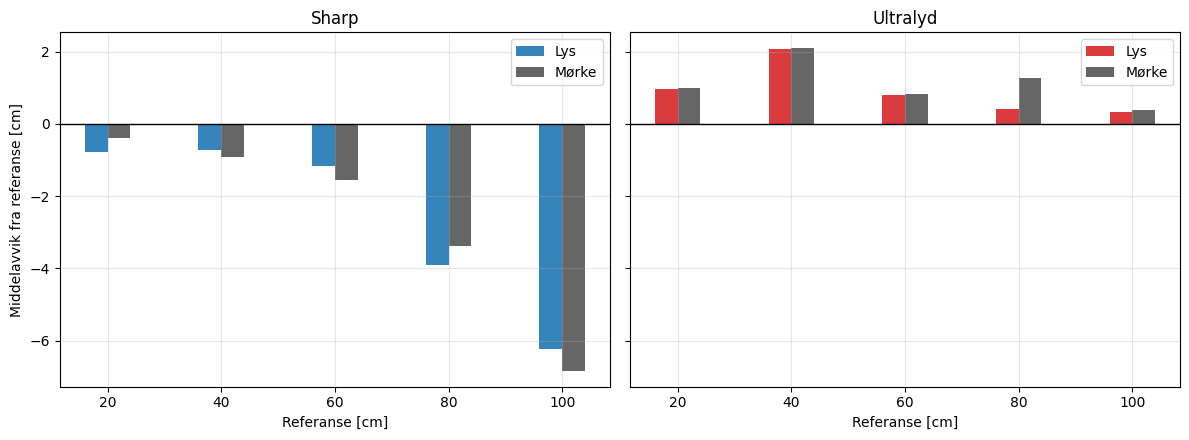

In [26]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (navn, lys, mork, f) in zip(axs, [("Sharp", tab_sharp_lys, tab_sharp_mork, FARGE["sharp"]),
                                         ("Ultralyd", tab_ultra_lys, tab_ultra_mork, FARGE["ultra"])]):
    l = lys.groupby("ref [cm]")["avvik [cm]"].mean()
    m = mork.groupby("ref [cm]")["avvik [cm]"].mean()
    b = 4
    ax.bar(l.index - b/2, l.values, width=b, color=f, alpha=0.9, label="Lys")
    ax.bar(m.index + b/2, m.values, width=b, color="k", alpha=0.6, label="Mørke")
    ax.axhline(0, color="k", lw=1)
    ax.set_title(navn); ax.set_xlabel("Referanse [cm]"); ax.legend()
    print(f"{navn:9s} middel |lys − mørke| = {np.mean(np.abs(l - m)):.2f} cm")
axs[0].set_ylabel("Middelavvik fra referanse [cm]")
plt.tight_layout(); plt.show()

## Sammenligning 5 – Ulike hindringer (Sharp)

Sharp mot standard objekt (lys-serien) vs. treplate.

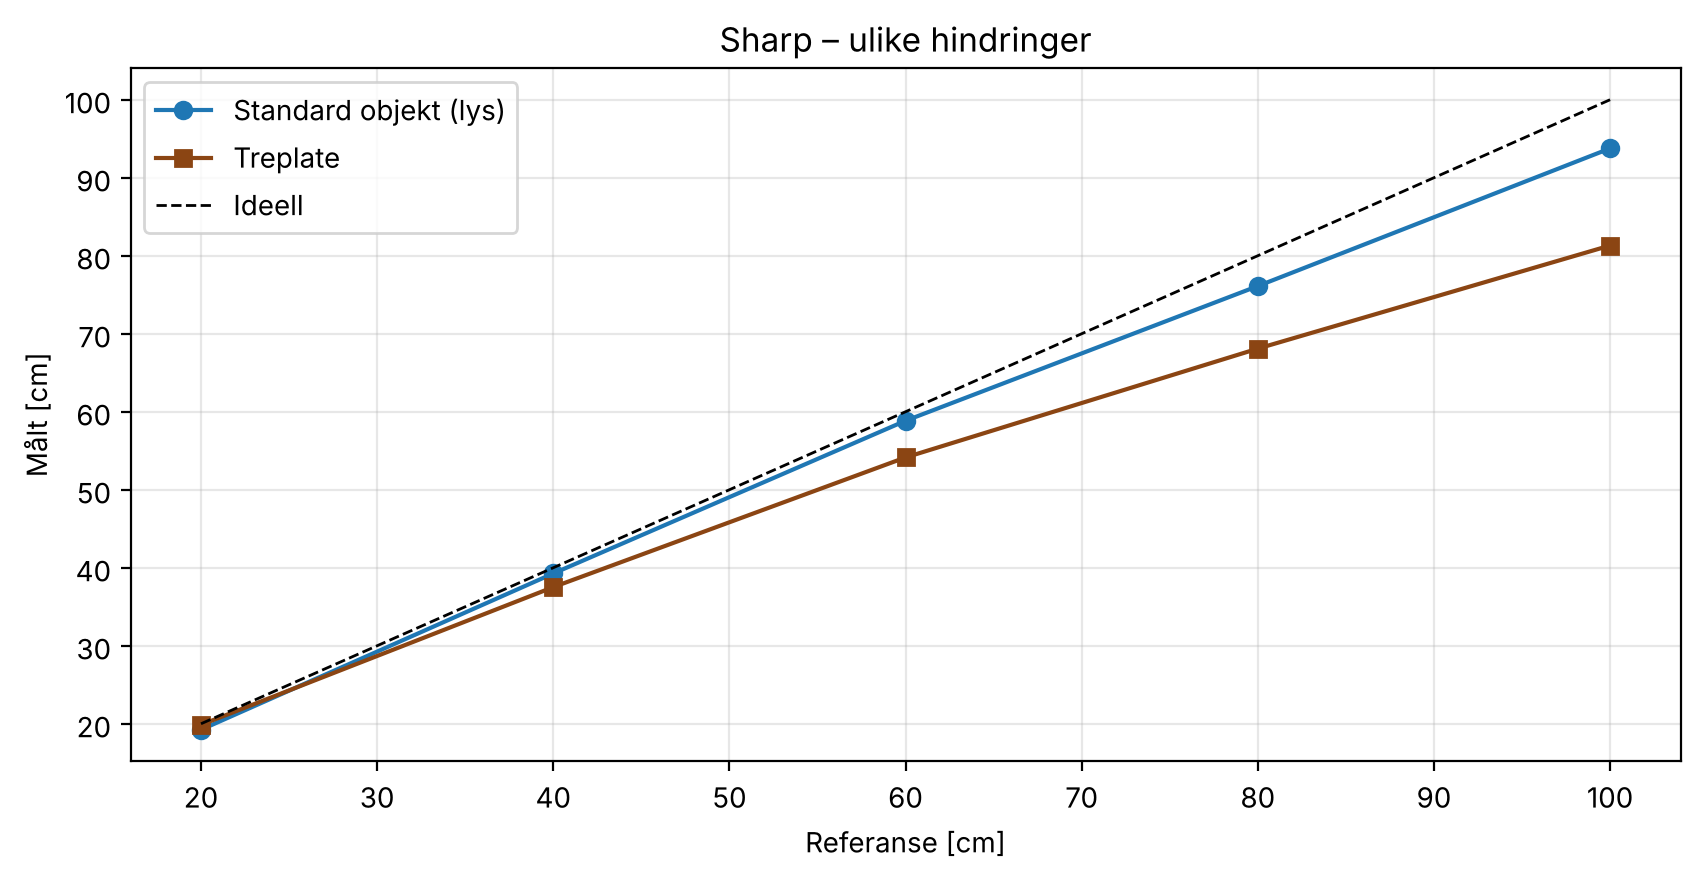

,standard [cm],treplate [cm],differanse [cm]
ref [cm],,,
20,19.24,19.86,0.62
40,39.27,37.52,-1.75
60,58.84,54.14,-4.70
80,76.11,68.09,-8.02
100,93.76,81.31,-12.45


In [17]:
std_obj = tab_sharp_lys.groupby("ref [cm]")["middel [cm]"].mean()
tre = tab_treplate.set_index("ref [cm]")["middel [cm]"]

fig, ax = plt.subplots()
ax.plot(std_obj.index, std_obj.values, "o-", color=FARGE["sharp"], label="Standard objekt (lys)")
ax.plot(tre.index, tre.values, "s-", color="saddlebrown", label="Treplate")
ax.plot([20, 100], [20, 100], "k--", lw=1, label="Ideell")
ax.set_xlabel("Referanse [cm]"); ax.set_ylabel("Målt [cm]"); ax.set_title("Sharp – ulike hindringer"); ax.legend()
plt.show()

pd.DataFrame({"standard [cm]": std_obj, "treplate [cm]": tre, "differanse [cm]": tre - std_obj}).round(2)

## Oppsummering – samlet tabell

In [18]:
rader = []
for navn, tab in [("Sharp lys", tab_sharp_lys), ("Ultralyd lys", tab_ultra_lys),
                  ("Sharp mørke", tab_sharp_mork), ("Ultralyd mørke", tab_ultra_mork),
                  ("Sharp treplate", tab_treplate)]:
    h = hysterese(tab)
    rader.append({"serie": navn,
                  "maks |avvik| [cm]": tab["avvik [cm]"].abs().max(),
                  "ulinearitet [% FS]": tab["avvik [cm]"].abs().max() / 80 * 100,
                  "snitt std platå [cm]": tab["std [cm]"].mean(),
                  "maks |hysterese| [cm]": h["ned - opp [cm]"].abs().max() if len(h) else np.nan})
pd.DataFrame(rader).round(2)

,serie,maks |avvik| [cm],ulinearitet [% FS],snitt std platå [cm],maks |hysterese| [cm]
0,Sharp lys,6.24,7.80,0.10,0.75
1,Ultralyd lys,3.45,4.31,0.12,2.76
2,Sharp mørke,6.83,8.53,0.15,3.14
3,Ultralyd mørke,3.38,4.23,0.19,2.59
4,Sharp treplate,18.69,23.36,0.08,NaN


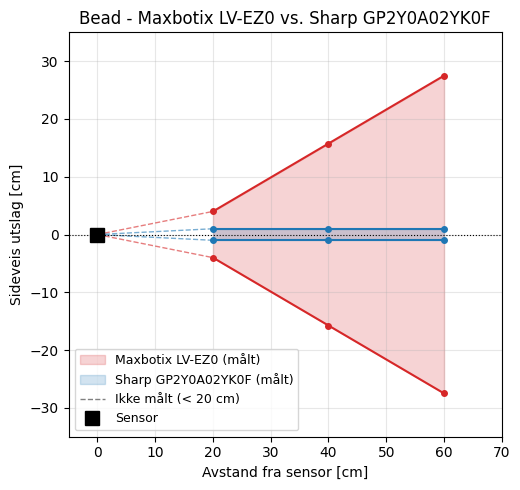

Maxbotix LV-EZ0      åpningsvinkel ≈ 49°
Sharp GP2Y0A02YK0F   åpningsvinkel ≈ 2°


In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Målte punkter: avstand fra sensor [cm] og halv bredde av strålen [cm]
d = np.array([20, 40, 60])
b_ultra = np.array([4, 15.75, 27.5])   # Maxbotix LV-EZ0
b_sharp = np.array([1, 1, 1])          # Sharp GP2Y0A02YK0F

R, B = "#d62728", "#1f77b4"

fig, ax = plt.subplots(figsize=(9, 5))

for b, f, navn in [(b_ultra, R, "Maxbotix LV-EZ0 (målt)"), (b_sharp, B, "Sharp GP2Y0A02YK0F (målt)")]:
    ax.fill_between(d, -b, b, color=f, alpha=0.2, label=navn)
    ax.plot(d,  b, "-o", color=f, ms=4)
    ax.plot(d, -b, "-o", color=f, ms=4)
    # Ikke målt: stiplet fra sensor til første målepunkt
    ax.plot([0, d[0]], [0,  b[0]], "--", color=f, lw=1, alpha=0.6)
    ax.plot([0, d[0]], [0, -b[0]], "--", color=f, lw=1, alpha=0.6)

ax.plot([], [], "--", color="gray", lw=1, label="Ikke målt (< 20 cm)")
ax.plot(0, 0, "ks", ms=10, label="Sensor")

ax.axhline(0, color="k", lw=0.8, ls=":")
ax.set_xlabel("Avstand fra sensor [cm]")
ax.set_ylabel("Sideveis utslag [cm]")
ax.set_title("Bead - Maxbotix LV-EZ0 vs. Sharp GP2Y0A02YK0F")
ax.set_xlim(-5, 70)
ax.set_ylim(-35, 35)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

# Oppsummering: full åpningsvinkel ved lengste målte avstand (60 cm)
for navn, b in [("Maxbotix LV-EZ0", b_ultra), ("Sharp GP2Y0A02YK0F", b_sharp)]:
    vinkel = 2 * np.degrees(np.arctan(b[-1] / d[-1]))
    print(f"{navn:20s} åpningsvinkel ≈ {vinkel:.0f}°")

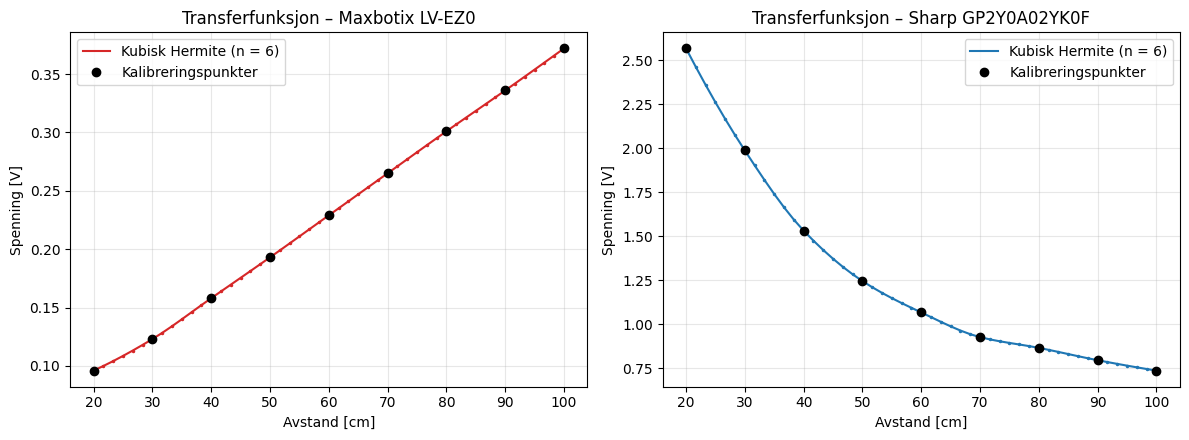

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator   # kubisk Hermite (monoton), som i Interpolate 1D

N = 6   # antall interpolerte punkter per intervall mellom kalibreringspunktene

def les_kal(fil):
    return pd.read_csv(fil, sep=r"\s+", header=None, names=["d", "V"], decimal=",")

kal = {
    "Maxbotix LV-EZ0":    (les_kal("maxbotix_sonic_kalibreringsdata.txt"),   "#d62728"),
    "Sharp GP2Y0A02YK0F": (les_kal("sharp_kalibreringsdata_fra_adc.txt"),    "#1f77b4"),
}

def interp_grid(x, n):
    """n punkter per intervall (inkl. startpunktet), pluss siste kalibreringspunkt."""
    return np.concatenate([np.linspace(x[i], x[i+1], n, endpoint=False) for i in range(len(x) - 1)] + [[x[-1]]])

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (navn, (df, farge)) in zip(axs, kal.items()):
    d, V = df["d"].values, df["V"].values
    f = PchipInterpolator(d, V)
    dx = interp_grid(d, N)

    ax.plot(dx, f(dx), "-", color=farge, label=f"Kubisk Hermite (n = {N})")
    ax.plot(dx, f(dx), ".", color=farge, ms=3)
    ax.plot(d, V, "ko", label="Kalibreringspunkter")
    ax.set_xlabel("Avstand [cm]")
    ax.set_ylabel("Spenning [V]")
    ax.set_title(f"Transferfunksjon - {navn}")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()